# Full multimodal analysis, step by step

The analysis of
[`multimodal-full.workflow.yaml`](../../examples/multimodal_full/multimodal-full.workflow.yaml),
run one step at a time in a notebook instead of with `m3resp run`: the full EIT,
EMG and ventilator processing, with the EMG breath features and quality checks.

Every call lists all the settings the function takes. Settings the workflow file
sets have its values; the others are at their defaults.

## 1. Import the required libraries

In [1]:
from pathlib import Path

from m3resp import M3Session
from m3resp.visualization import plot_synchronization_comparison
from m3resp.workflows.steps import eit, emg, sync, ventilator

## 2. Load the EIT, EMG and ventilator data

In [2]:
data_dir = Path("../../tests/data")

session = M3Session()
eit_data = eit.load(
    session,
    file_path=data_dir / "m3resp_multimodal_1_eit_draeger.bin",
    vendor="draeger",  # "draeger", "sentec" or "timpel"
    sample_frequency=None,  # None: from the file (Draeger)
    first_frame=0,
    max_frames=None,  # None: read to the end
    loader_options=None,  # extra settings for the vendor loader
)
emg.load(
    session,
    file_path=data_dir / "m3resp_multimodal_1_emg.Poly5",
    loader_options=None,  # extra settings for M3Session.load_emg
)
vent_data = ventilator.load(
    session,
    file_path=data_dir / "m3resp_multimodal_1_ventilator.Poly5",
    source=None,  # which device's file this is; decides its clock
    name=None,  # name for this recording, when loading several
)

Reading file  ..\..\tests\data\m3resp_multimodal_1_emg.Poly5
	 Number of samples:  122880 
	 Number of channels:  2 
	 Sample rate: 2048 Hz
Done reading data.
Reading file  ..\..\tests\data\m3resp_multimodal_1_ventilator.Poly5
	 Number of samples:  6000 
	 Number of channels:  3 
	 Sample rate: 100 Hz
Done reading data.


In [3]:
# Put the recordings on one clock, before any processing: the EMG recording
# started 2 s earlier
sync.raw_modalities(
    session,
    method="manual_offset",  # the only method
    offset_seconds={"eit": 0.0, "emg": -2.0, "vent": 0.0},
    reference_modality="vent",
)
session.start_times

{'eit': 0.0, 'emg': -2.0, 'ventilator': 0.0}

## 3. Process the EIT data

In [4]:
# Respiratory and heart rate
rates = eit.detect_rates(
    eit_data["raw_eit"],
    session=session,
    subject_type="adult",  # "adult" or "neonate"
    welch_window_seconds=30.0,  # None: the detector's default of 30 s
    capture=True,  # keep intermediate results for the figures
)
rates["respiratory_rate_hz"] * 60, rates["heart_rate_hz"] * 60  # per minute

(13.883484475314617, 95.75131922960281)

In [5]:
# Remove the cardiac component, then sum all pixels
filtered_eit = eit.mdn_filter(
    eit_data["raw_eit"],
    respiratory_rate_hz=rates["respiratory_rate_hz"],
    heart_rate_hz=rates["heart_rate_hz"],
    eit_sequence=eit_data["eit_sequence"],
    session=session,
    label="mdn_filtered",
)["filtered_eit"]
global_impedance = eit.global_impedance(
    filtered_eit,
    eit_sequence=eit_data["eit_sequence"],
)["global_impedance"]

In [6]:
# Find the breaths and store them in the session
eit_breaths = eit.detect_breaths(
    global_impedance,
    min_duration_s=0.6666666667,
)
eit.normalize_breaths(
    eit_breaths["breath_intervals"],
    session=session,
)
len(session.events["eit_breaths"])

13

In [7]:
# Tidal impedance variation and end-expiratory lung impedance per breath
tiv = eit.continuous_tiv(
    global_impedance,
    eit_sequence=eit_data["eit_sequence"],
    breath_detector=eit_breaths["breath_detector"],
    session=session,
)
eeli = eit.eeli(
    global_impedance,
    eit_sequence=eit_data["eit_sequence"],
    breath_detector=eit_breaths["breath_detector"],
    session=session,
    result_label="continuous_eelis",
)

In [8]:
# Breaths per pixel, and the TIV of each pixel per breath
pixel_breaths = eit.pixel_breaths(
    eit_data=filtered_eit,
    timing_data=global_impedance,
    eit_sequence=eit_data["eit_sequence"],
    session=session,
    # "negative amplitude", "phase shift", or "none"/None for no correction
    phase_correction_mode="negative amplitude",
    minimum_duration_seconds=2 / 3,
    result_label="pixel_breaths",
)
pixel_tiv = eit.pixel_tiv(
    eit_data=filtered_eit,
    signal=global_impedance,
    eit_sequence=eit_data["eit_sequence"],
    breath_detector=eit_breaths["breath_detector"],
    session=session,
    tiv_timing="continuous",  # "continuous" (from signal) or "pixel"
    result_label="pixel_tivs",
)

In [9]:
# Regions of interest: three ways to find the lung space, and the watershed
# region with its small islands removed
tiv_lungspace_mask = eit.roi_tiv_lungspace(
    eit_data=filtered_eit,
    timing_data=global_impedance,
    session=session,
    threshold=0.15,  # fraction of the maximum mean pixel TIV
)["tiv_lungspace_mask"]
amplitude_lungspace_mask = eit.roi_amplitude_lungspace(
    eit_data=filtered_eit,
    timing_data=global_impedance,
    session=session,
    threshold=0.15,  # fraction of the maximum mean pixel amplitude
)["amplitude_lungspace_mask"]
watershed_lungspace_mask = eit.roi_watershed(
    eit_data=filtered_eit,
    timing_data=global_impedance,
    session=session,
    threshold_fraction=0.15,
)["watershed_lungspace_mask"]
size_filtered_roi_mask = eit.roi_filter_by_size(
    watershed_lungspace_mask,
    session=session,
    min_region_size=10,  # smallest connected region kept, in pixels
    connectivity=1,  # 1: 4-connected, 2: 8-connected
)["size_filtered_roi_mask"]

## 4. Process the EMG data

Channel 1 is the diaphragm EMG. The ECG is mixed into it and there is no
separate ECG channel, so the ECG peaks are found in channel 1 too.

In [10]:
# Filter
emg_filtered = emg.preprocess(
    session,
    channel=1,  # None: chosen from the channel labels
    high_pass_hz=20,
    low_pass_hz=None,  # None: 500 Hz, or 95 % of Nyquist if lower
    notch_base_frequency=None,  # e.g. 50 for mains hum; None: no notch filter
    notch_max_frequency=None,  # None: Nyquist
    notch_quality_factor=30.0,
    notch_before_bandpass=False,
    variant=None,  # store under a named variant instead of the default
)["processed_emg"]

In [11]:
# ECG removal: find the ECG peaks, then gate them out
ecg_peak_indices = emg.ecg_detect_peaks(
    session,
    emg_filtered,
    ecg_channel=None,  # raw channel with the ECG; overrides source
    source="raw_channel",  # key of emg_filtered to detect the ECG in
    peak_fraction=0.4,
    peak_width_seconds=None,  # None: the detector's choice
    peak_distance_seconds=0.33,
    bandpass_filter=True,
)["ecg_peak_indices"]
emg_gated = emg.ecg_gating(
    session,
    emg_filtered,
    ecg_peak_indices,
    source=None,  # None: the ECG-cleaned trace if present, else filtered
    gate_width_seconds=None,  # set this or gate_width_samples, not both
    gate_width_samples=None,  # None: 205 samples
    fill_method=1,  # 0 zeros, 1 interpolation, 2 neighbour mean, 3 running RMS
)["processed_emg_after_ecg"]
len(ecg_peak_indices)

28

In [12]:
# Envelope
emg_processed = emg.envelope(
    session,
    emg_gated,
    window_seconds=0.25,
    method="rms",  # "rms", "arv" or "median"
    source=None,  # None: the ECG-cleaned trace if present, else filtered
)["processed_emg_with_envelope"]

## 5. Find the EMG breaths

The baseline comes first: a breath is a rise above the local quiet level, and
the detection threshold is taken from the envelope above that level.

In [13]:
baseline = emg.slopesum_baseline(
    session,
    emg_processed,
    window_seconds=7.5,
    step_seconds=0.2,
    percentile=33.0,
    augmented_percentile=25.0,
    moving_average_seconds=0.5,
    percentile_window_seconds=1.0,
)["baseline"]

emg_breaths = emg.detect_breaths(
    session,
    baseline=baseline,
    variant=None,  # detect in a named preprocessing variant
    min_breath_width_seconds=0.85,
    distance_seconds=0.5,  # minimum time between breath peaks
    threshold=0,
    prominence_factor=0.5,
)["emg_breath_events"]
peak_indices = emg.peak_indices(emg_breaths, emg_processed)["peak_indices"]
len(emg_breaths)

14

In [14]:
vent_signals = ventilator.channels(
    vent_data["ventilator_raw"],
    channels=("airway_pressure", "flow", "volume"),
    airway_pressure_channel=0,  # None: found by channel label
    flow_channel=1,
    volume_channel=2,
    fs=None,  # None: from the recording
)["ventilator_signals"]

In [15]:
# Start and end of each EMG breath: where the envelope crosses the baseline
onoff = emg.onoffpeak_baseline_crossing(session, emg_processed, baseline, peak_indices)
start_indices = onoff["start_indices"]
end_indices = onoff["end_indices"]

## 6. Calculate the EMG breath features

In [16]:
time_to_peak = emg.time_to_peak(emg_processed, start_indices, end_indices)[
    "time_to_peak"
]
pseudo_slope = emg.pseudo_slope(emg_processed, start_indices, end_indices)[
    "pseudo_slope"
]
amplitude = emg.amplitude(emg_processed, peak_indices, baseline)["amplitude"]
time_product = emg.time_product(emg_processed, start_indices, end_indices, baseline)[
    "time_product"
]
area_under_baseline = emg.area_under_baseline(
    emg_processed,
    peak_indices,
    start_indices,
    end_indices,
    baseline,
    window_seconds=5.0,  # window around each peak
)["area_under_baseline"]
respiratory_rate = emg.respiratory_rate(peak_indices, emg_processed)["respiratory_rate"]
respiratory_rate

(13.853438556933483,
 array([15.82893211, 13.05151354, 13.91619479, 13.75265809, 13.81450253,
        15.20603886, 12.95382669, 15.32934132, 13.14646411, 14.91081179,
        13.27858223, 14.09821019, 13.85343856]))

## 7. Find the occlusion manoeuvres (Pocc) and the ventilator breaths

In [17]:
# Occlusions: find them, their start and end, their pressure-time product and
# their quality
pocc_indices = ventilator.find_occluded_breaths(
    vent_signals,
    peep=None,  # None: estimated from the end-expiratory pressure
)["pocc_indices"]
pocc = ventilator.pocc_intervals(
    session,
    vent_signals,
    pocc_indices,
    baseline_window_seconds=7.5,
    baseline_step_seconds=0.2,
    baseline_percentile=33.0,
)
pocc_time_products = ventilator.pocc_time_product(
    session,
    vent_signals,
    pocc["pocc_start_indices"],
    pocc["pocc_end_indices"],
    pocc["pressure_baseline"],
    pocc_indices=pocc_indices,
    include_aub=True,  # add the area under the baseline
    aub_window_seconds=5.0,
)["pocc_time_products"]
pocc_quality = ventilator.pocc_quality(
    session,
    vent_signals,
    pocc_indices,
    pocc["pocc_end_indices"],
    pocc_time_products,
    dp_up_10_threshold=0.0,
    dp_up_90_threshold=2.0,
    dp_up_90_norm_threshold=0.8,
)["pocc_quality"]
pocc_time_products, pocc_quality

(array([3.91020645, 5.2099872 ]), array([ True,  True]))

In [18]:
# Ventilator breaths
vent_breath_indices = ventilator.detect_breaths(
    vent_signals,
    breath_width_seconds=0.5,
)["ventilator_breath_indices"]
vent_respiratory_rate = ventilator.respiratory_rate(vent_breath_indices, vent_signals)[
    "ventilator_respiratory_rate"
]
non_consecutive_manoeuvres = ventilator.detect_non_consecutive_manoeuvres(
    session, vent_breath_indices, pocc_indices
)["detect_non_consecutive_manoeuvres"]
ventilator.normalize_breaths(
    vent_breath_indices,
    vent_signals,
    session,
    breath_width_seconds=0.5,
)
vent_respiratory_rate

(13.986013986013987,
 array([15.18987342, 13.98601399, 14.01869159, 13.98601399, 14.01869159,
        13.98601399, 14.01869159, 13.98601399, 13.98601399, 14.01869159,
         7.00116686, 13.98601399]))

## 8. Test the EMG quality

Each check stores one quality flag per breath (or one for the recording) in
`session.quality`.

In [19]:
snr = emg.snr_pseudo(
    session,
    emg_processed,
    peak_indices,
    baseline,
    minimum_snr=None,  # None: measure only, no pass/fail flags
)["snr_pseudo"]
percentage_under_baseline = emg.percentage_under_baseline(
    session,
    emg_processed,
    peak_indices,
    start_indices,
    end_indices,
    baseline,
    aub_window_seconds=None,  # None: each breath's own start-end window
    aub_threshold=40.0,  # maximum percentage under the baseline
)["percentage_under_baseline"]
local_high_aub = emg.detect_local_high_aub(
    session,
    area_under_baseline,
    peak_indices,
    threshold_percentile=75.0,
    threshold_factor=4.0,
)["detect_local_high_aub"]
extreme_time_products = emg.detect_extreme_time_products(
    session,
    time_product,
    peak_indices,
    upper_percentile=95.0,
    upper_factor=10.0,
    lower_percentile=5.0,
    lower_factor=0.1,
)["detect_extreme_time_products"]

In [20]:
bell_curve_error = emg.evaluate_bell_curve_error(
    session, peak_indices, start_indices, end_indices, emg_processed, time_product
)["evaluate_bell_curve_error"]
event_timing = emg.evaluate_event_timing(
    session, peak_indices, emg_processed, vent_breath_indices, vent_signals
)["evaluate_event_timing"]
respiratory_rates_agree = emg.evaluate_respiratory_rates(
    session,
    peak_indices,
    emg_processed,
    vent_respiratory_rate,
    minimum_fraction=0.1,  # minimum fraction of expected EMG breaths found
)["evaluate_respiratory_rates"]
interpeak_distance = emg.interpeak_dist(
    session,
    ecg_peak_indices,
    peak_indices,
    emg_processed,
    threshold=1.1,  # maximum EMG/ECG interpeak distance ratio
)["interpeak_dist"]

## 9. Results

In [21]:
{name: len(events) for name, events in session.events.items()}

{'eit_breaths': 13,
 'ecg_peaks': 28,
 'emg_breaths': 14,
 'pocc_breaths': 2,
 'ventilator_breaths': 13}

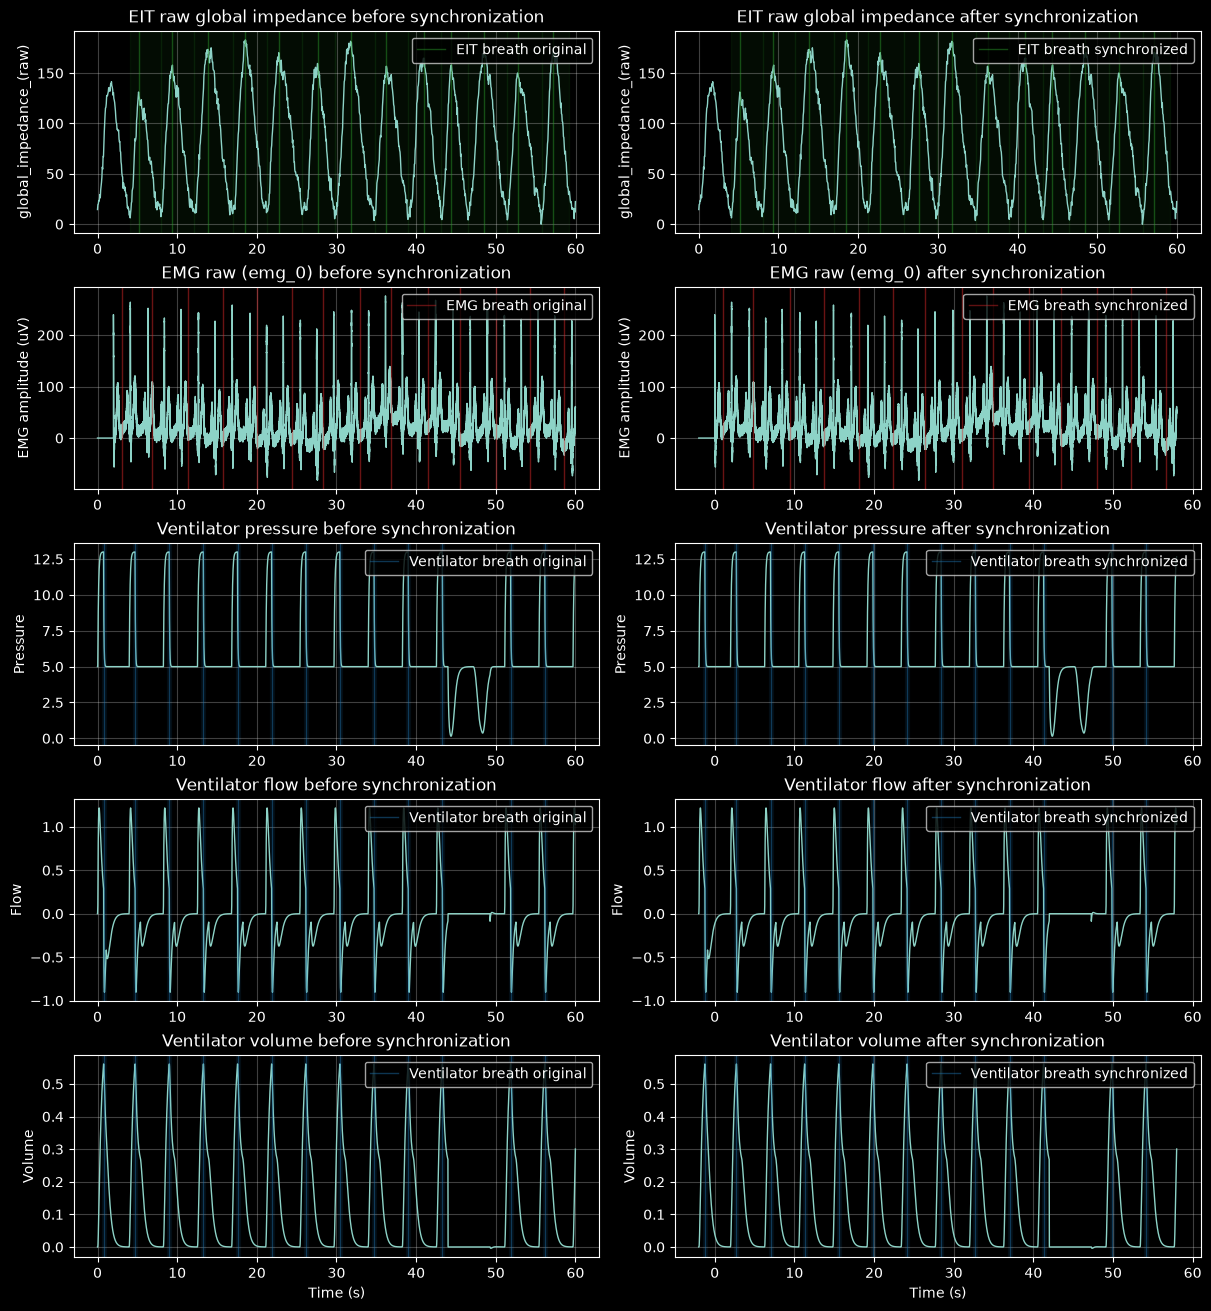

In [22]:
# Each signal with its breaths, before and after synchronization
fig = plot_synchronization_comparison(
    session,
    max_seconds=120.0,  # None: the whole recording
    emg_channel=1,  # the channel the EMG processing used
    eit_waveform="global_impedance_(raw)",
    backend="matplotlib",  # or "plotly"
    max_points=5000,
)